# Teste do modelo final em gatos e cachorros dos alunos do Impa-Tech

Aqui o modelo final (`modelo_cats_and_dogs_224_v2.pt`) é testado em fotos que **não** vieram do Kaggle, na pasta `Banco de dados - Pets` (`Gatos/` e `Cachorros/`) - Banco de dados do IMPA-Tech

O modelo não é treinado nem alterado. O pré-processamento é o mesmo do notebook `cats_and_dogs_224_v2.ipynb`: lado menor vira 224, corte central e interpolação bilinear.

In [2]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

try:
    import pillow_heif          # só necessário para arquivos .HEIC
    pillow_heif.register_heif_opener()
except ImportError:
    pass

PASTA_FOTOS = "Banco de dados - Pets"
ALTURA, LARGURA = 224, 224
CLASSES = ["Cat", "Dog"]                       # ordem alfabética, como no treino
NOMES = ["gato", "cachorro"]
PASTA_CLASSE = {"Gatos": 0, "Cachorros": 1}

## Modelo
A mesma rede do notebook de treino, com os pesos da melhor época.

In [3]:
FILTROS = [32, 64, 64, 128, 128]

class Rede(nn.Module):
    def __init__(self, altura, largura):
        super().__init__()
        blocos, canais = [], 3
        for filtros in FILTROS:
            blocos += [nn.Conv2d(canais, filtros, kernel_size=5, stride=1, padding=1),
                       nn.ReLU(), nn.MaxPool2d(kernel_size=2, stride=2), nn.Dropout(0.2)]
            canais = filtros
        self.convolucoes = nn.Sequential(*blocos)
        for _ in range(5):
            altura = (altura - 2) // 2
            largura = (largura - 2) // 2
        self.conectadas = nn.Sequential(
            nn.Flatten(),
            nn.Linear(FILTROS[-1] * altura * largura, 1024), nn.ReLU(),
            nn.Linear(1024, 32), nn.ReLU(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        return torch.softmax(self.conectadas(self.convolucoes(x)), dim=1)

modelo = Rede(ALTURA, LARGURA)
modelo.load_state_dict(torch.load("modelo_cats_and_dogs_224_v2.pt", map_location="cpu"))
modelo.eval()
print("Modelo carregado.")

Modelo carregado.


## Pré-processamento e previsão

In [4]:
def redimensionar(img):
    # Igual ao notebook de treino: lado menor vira 224, o excesso do maior é cortado no centro.
    h, w = img.shape[:2]
    escala = max(ALTURA / h, LARGURA / w)
    corte_h, corte_w = min(ALTURA / escala, h), min(LARGURA / escala, w)
    esquerda, topo = max((w - corte_w) / 2, 0), max((h - corte_h) / 2, 0)
    pil = Image.fromarray(np.clip(np.rint(img), 0, 255).astype(np.uint8))
    nova = pil.resize((LARGURA, ALTURA), Image.BILINEAR,
                      box=(esquerda, topo, esquerda + corte_w, topo + corte_h))
    return np.asarray(nova, dtype=np.float32)

def preparar(im):
    # Devolve a imagem 224 x 224 (uint8) que entra no modelo.
    x = np.asarray(im.convert("RGB"), dtype=np.float32)
    return np.clip(np.rint(redimensionar(x)), 0, 255).astype(np.uint8)

def prever(x_uint8):
    t = torch.from_numpy(x_uint8).permute(2, 0, 1).float().div(255)[None]
    with torch.no_grad():
        return modelo(t)[0]

## Rodando nas fotos

Cada foto é avaliada de dois jeitos:
* **sem EXIF**: como o notebook de treino faz (ele ignora a rotação gravada pelo celular);
* **com EXIF**: aplicando a rotação gravada na foto, para fotos tiradas em pé não entrarem deitadas.

In [5]:
resultados = {"sem EXIF": [], "com EXIF": []}
nao_abriram = []

for pasta, real in PASTA_CLASSE.items():
    for nome in sorted(os.listdir(os.path.join(PASTA_FOTOS, pasta))):
        arquivo = os.path.join(PASTA_FOTOS, pasta, nome)
        try:
            with Image.open(arquivo) as im:
                im.load()
                sem = preparar(im)
                com = preparar(ImageOps.exif_transpose(im))
        except Exception:
            nao_abriram.append(arquivo)
            continue
        resultados["sem EXIF"].append(dict(pasta=pasta, nome=nome, real=real, img=sem, prob=prever(sem)))
        resultados["com EXIF"].append(dict(pasta=pasta, nome=nome, real=real, img=com, prob=prever(com)))

print("Fotos avaliadas:", len(resultados["sem EXIF"]))
print("Não abriram:", [os.path.basename(a) for a in nao_abriram])

Fotos avaliadas: 77
Não abriram: ['IMG_9621.HEIC']


## Acurácia

In [6]:
def acertou(r):
    return int(r["prob"].argmax()) == r["real"]

for modo, lista in resultados.items():
    print(f"=== {modo} ===")
    for pasta in PASTA_CLASSE:
        sub = [r for r in lista if r["pasta"] == pasta]
        a = sum(map(acertou, sub))
        print(f"{pasta:10s} {a}/{len(sub)} ({a / len(sub):.1%})")
    a = sum(map(acertou, lista))
    print(f"{'TOTAL':10s} {a}/{len(lista)} ({a / len(lista):.1%})\n")

=== sem EXIF ===
Gatos      30/45 (66.7%)
Cachorros  29/32 (90.6%)
TOTAL      59/77 (76.6%)

=== com EXIF ===
Gatos      35/45 (77.8%)
Cachorros  30/32 (93.8%)
TOTAL      65/77 (84.4%)



## Matriz de confusão

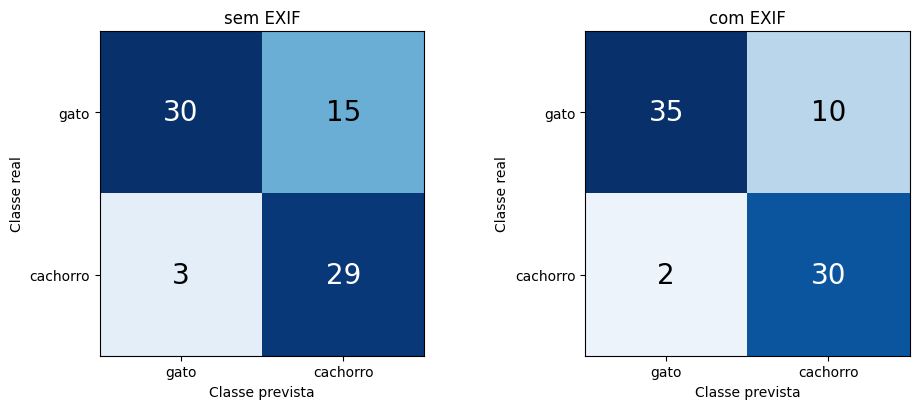

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (modo, lista) in zip(eixos, resultados.items()):
    matriz = np.zeros((2, 2), dtype=int)
    for r in lista:
        matriz[r["real"], int(r["prob"].argmax())] += 1
    ax.imshow(matriz, cmap="Blues", vmin=0)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, matriz[i, j], ha="center", va="center", fontsize=20,
                    color="white" if matriz[i, j] > matriz.max() / 2 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=NOMES, yticklabels=NOMES,
           xlabel="Classe prevista", ylabel="Classe real", title=modo)
fig.tight_layout()
plt.show()

## Erros (com EXIF)
Do mais confiante para o menos confiante.

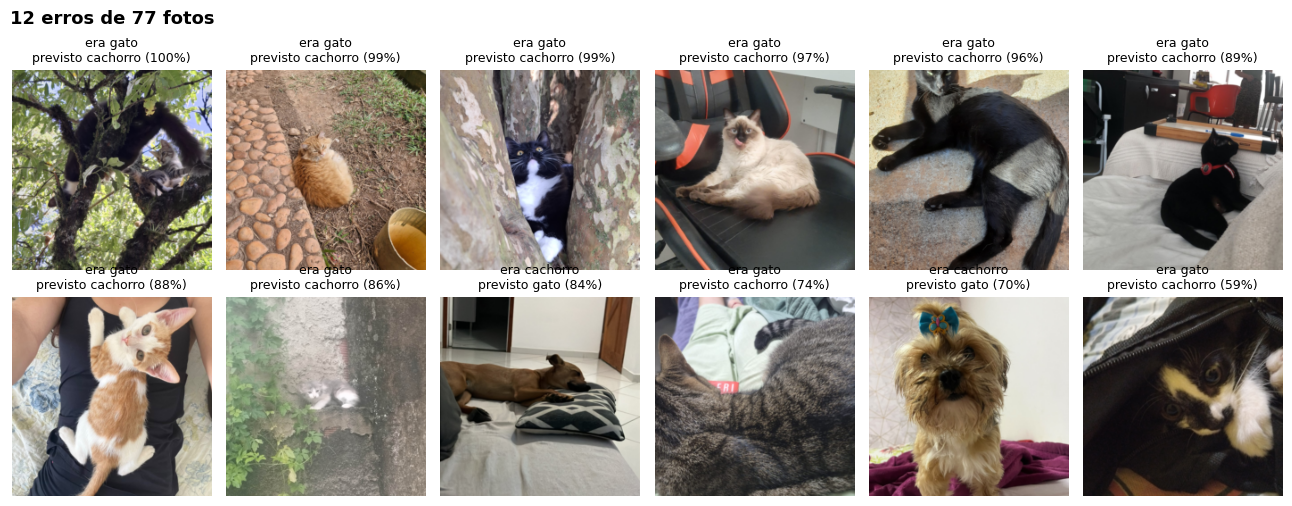

In [8]:
erros = [r for r in resultados["com EXIF"] if not acertou(r)]
erros.sort(key=lambda r: -float(r["prob"].max()))

colunas = 6
linhas = int(np.ceil(len(erros) / colunas))
fig, eixos = plt.subplots(linhas, colunas, figsize=(13, 2.6 * linhas), squeeze=False)
for ax in eixos.ravel():
    ax.axis("off")
for ax, r in zip(eixos.ravel(), erros):
    ax.imshow(r["img"])
    previsto = int(r["prob"].argmax())
    ax.set_title(f"era {NOMES[r['real']]}\nprevisto {NOMES[previsto]} ({r['prob'].max():.0%})", fontsize=9)
fig.suptitle(f"{len(erros)} erros de {len(resultados['com EXIF'])} fotos", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()